In [5]:
import numpy as np

x_difference = -0.11789663
y_difference = 0.00644788

distance = np.linalg.norm([x_difference, y_difference])
print(distance)

0.11807281872578167


In [10]:
import gymnasium as gym 
import numpy as np

env  = gym.make("Reacher-v5", render_mode="human")

import numpy as np

observation, info = env.reset(seed=42)
action = np.array([0.05, -0.10])

start_distance = np.linalg.norm(observation[8:10])
print(f"Start: distance = {start_distance:.6f}")

step_number = 0
terminated = False
truncated = False

while not (terminated or truncated):
    observation, reward, terminated, truncated, info = env.step(action)
    step_number += 1

    distance = np.linalg.norm(observation[8:10])
    print(f"Step {step_number}: distanc{reward:.6f}")

env.close()

Start: distance = 0.148185
Step 1: distanc-0.160710
Step 2: distanc-0.160757
Step 3: distanc-0.160815
Step 4: distanc-0.160868
Step 5: distanc-0.160896
Step 6: distanc-0.160871
Step 7: distanc-0.160764
Step 8: distanc-0.160540
Step 9: distanc-0.160162
Step 10: distanc-0.159593
Step 11: distanc-0.158795
Step 12: distanc-0.157732
Step 13: distanc-0.156373
Step 14: distanc-0.154692
Step 15: distanc-0.152677
Step 16: distanc-0.150330
Step 17: distanc-0.147674
Step 18: distanc-0.144760
Step 19: distanc-0.141677
Step 20: distanc-0.138559
Step 21: distanc-0.135591
Step 22: distanc-0.133025
Step 23: distanc-0.131170
Step 24: distanc-0.130385
Step 25: distanc-0.131044
Step 26: distanc-0.133491
Step 27: distanc-0.137982
Step 28: distanc-0.144640
Step 29: distanc-0.153441
Step 30: distanc-0.164233
Step 31: distanc-0.169320
Step 32: distanc-0.166463
Step 33: distanc-0.162947
Step 34: distanc-0.160009
Step 35: distanc-0.157722
Step 36: distanc-0.155899
Step 37: distanc-0.154366
Step 38: distanc-0.1

In [12]:
import gymnasium as gym
import numpy as np

env = gym.make("Reacher-v5", render_mode="human")
observation, info = env.reset(seed=42)

action = np.array([0.05, -0.10], dtype=np.float32)
print(f"Start distance: {np.linalg.norm(observation[8:10]):.6f}")

step_number = 0
terminated = False
truncated = False

while not (terminated or truncated):
    observation, reward, terminated, truncated, info = env.step(action)
    step_number += 1
    distance = np.linalg.norm(observation[8:10])
    print(f"Step {step_number}: distance = {distance:.6f}, reward = {reward:.6f}")

env.close()    

Start distance: 0.148185
Step 1: distance = 0.148210, reward = -0.160710
Step 2: distance = 0.148257, reward = -0.160757
Step 3: distance = 0.148315, reward = -0.160815
Step 4: distance = 0.148368, reward = -0.160868
Step 5: distance = 0.148396, reward = -0.160896
Step 6: distance = 0.148371, reward = -0.160871
Step 7: distance = 0.148264, reward = -0.160764
Step 8: distance = 0.148040, reward = -0.160540
Step 9: distance = 0.147662, reward = -0.160162
Step 10: distance = 0.147093, reward = -0.159593
Step 11: distance = 0.146295, reward = -0.158795
Step 12: distance = 0.145232, reward = -0.157732
Step 13: distance = 0.143873, reward = -0.156373
Step 14: distance = 0.142192, reward = -0.154692
Step 15: distance = 0.140177, reward = -0.152677
Step 16: distance = 0.137830, reward = -0.150330
Step 17: distance = 0.135174, reward = -0.147674
Step 18: distance = 0.132260, reward = -0.144760
Step 19: distance = 0.129177, reward = -0.141677
Step 20: distance = 0.126059, reward = -0.138559
Step

Matplotlib is building the font cache; this may take a moment.


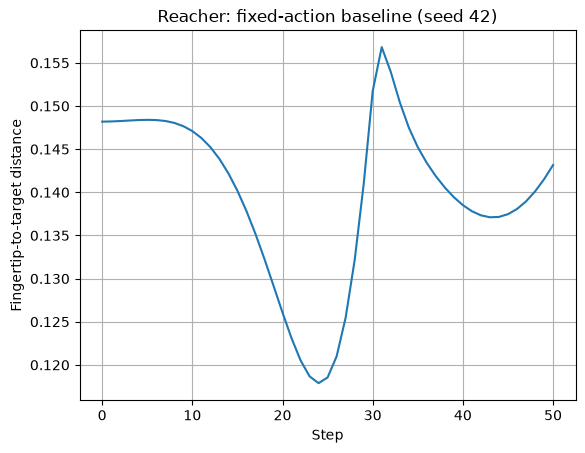

Closest distance: 0.117885 at step 24


In [14]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

env = gym.make("Reacher-v5", render_mode="human")
observation, info = env.reset(seed=42)
action = np.array([0.05, -0.10], dtype=np.float32)

distances = [np.linalg.norm(observation[8:10])]

terminated = False
truncated = False

while not (terminated or truncated):
    observation, reward, terminated, truncated, info = env.step(action)
    distances.append(np.linalg.norm(observation[8:10]))

env.close()

steps = range(len(distances))  # 0 is before the first action
plt.plot(steps, distances)
plt.xlabel("Step")
plt.ylabel("Fingertip-to-target distance")
plt.title("Reacher: fixed-action baseline (seed 42)")
plt.grid(True)
plt.show()

closest_step = int(np.argmin(distances))
print(f"Closest distance: {distances[closest_step]:.6f} at step {closest_step}")

- It starts around 0.148.
- It gets closest at about step 24–25, around 0.118.
- Then it moves sharply away, reaching about 0.157 near step 31.
- It comes closer again around step 43, but finishes around 0.143.

In [18]:
import gymnasium as gym
import numpy as np

env = gym.make("Reacher-v5", render_mode="human")
action = np.array([0.05, -0.10], dtype=np.float32)

print("Seed | Start distance | Closest distance | Final distance | Total reward")
print("-" * 75)

for seed in range(42, 52):
    observation, info = env.reset(seed=seed)
    start_distance = np.linalg.norm(observation[8:10])
    closest_distance = start_distance
    total_reward = 0.0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        observation, reward, terminated, truncated, info = env.step(action)

        distance = np.linalg.norm(observation[8:10])
        closest_distance = min(closest_distance, distance)
        total_reward += reward

    final_distance = distance
    print(
        f"{seed:4d} | {start_distance:14.6f} | {closest_distance:16.6f} "
        f"| {final_distance:14.6f} | {total_reward:12.6f}"
    )

env.close()

Seed | Start distance | Closest distance | Final distance | Total reward
---------------------------------------------------------------------------
  42 |       0.148185 |         0.117885 |       0.143159 |    -7.600587
  43 |       0.204758 |         0.100117 |       0.132823 |    -8.017413
  44 |       0.381065 |         0.184949 |       0.184949 |   -14.779082
  45 |       0.232501 |         0.094004 |       0.094014 |    -8.725283
  46 |       0.188319 |         0.103920 |       0.106769 |    -7.687580
  47 |       0.352997 |         0.172633 |       0.172633 |   -13.909960
  48 |       0.209893 |         0.139695 |       0.141191 |    -9.292453
  49 |       0.255981 |         0.145768 |       0.173213 |   -10.512340
  50 |       0.316714 |         0.111821 |       0.111821 |   -11.441349
  51 |       0.159109 |         0.112552 |       0.175248 |    -8.011542


Seed | Start distance | Closest distance | Final distance | Total reward
---------------------------------------------------------------------------
  42 |       0.148185 |         0.117885 |       0.143159 |    -7.600587
  43 |       0.204758 |         0.100117 |       0.132823 |    -8.017413
  44 |       0.381065 |         0.184949 |       0.184949 |   -14.779082
  45 |       0.232501 |         0.094004 |       0.094014 |    -8.725283
  46 |       0.188319 |         0.103920 |       0.106769 |    -7.687580
  47 |       0.352997 |         0.172633 |       0.172633 |   -13.909960
  48 |       0.209893 |         0.139695 |       0.141191 |    -9.292453
  49 |       0.255981 |         0.145768 |       0.173213 |   -10.512340
  50 |       0.316714 |         0.111821 |       0.111821 |   -11.441349
  51 |       0.159109 |         0.112552 |       0.175248 |    -8.011542


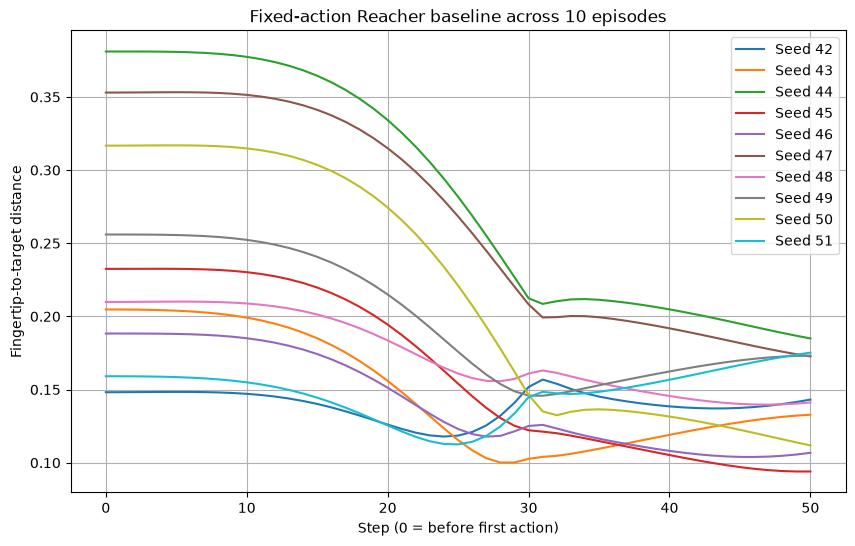

In [21]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

env = gym.make("Reacher-v5", render_mode="human")
action = np.array([0.05, -0.10], dtype=np.float32)

plt.figure(figsize=(10, 6))
print("Seed | Start distance | Closest distance | Final distance | Total reward")
print("-" * 75)

for seed in range(42, 52):
    observation, info = env.reset(seed=seed)
    distances = [np.linalg.norm(observation[8:10])]  # Step 0
    total_reward = 0.0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        observation, reward, terminated, truncated, info = env.step(action)
        distances.append(np.linalg.norm(observation[8:10]))
        total_reward += reward

    print(
        f"{seed:4d} | {distances[0]:14.6f} | {min(distances):16.6f} "
        f"| {distances[-1]:14.6f} | {total_reward:12.6f}"
    )

    plt.plot(range(len(distances)), distances, label=f"Seed {seed}")

env.close()

plt.xlabel("Step (0 = before first action)")
plt.ylabel("Fingertip-to-target distance")
plt.title("Fixed-action Reacher baseline across 10 episodes")
plt.grid(True)
plt.legend()
plt.show()

 all 10 episodes got closer to the target at some point—each “closest distance” is smaller than its starting distance. But they did not all finish at their closest point. For example, seed 51 reached about 0.113 and then finished farther away at 0.175. Seed 44 finished at its closest recorded distance, about 0.185.

# with threshold

Seed | Start distance | Closest distance | Final distance | Total reward | Success
-------------------------------------------------------------------------------------
  42 |       0.148185 |         0.117885 |       0.143159 |    -7.600587 | False
  43 |       0.204758 |         0.100117 |       0.132823 |    -8.017413 | False
  44 |       0.381065 |         0.184949 |       0.184949 |   -14.779082 | False
  45 |       0.232501 |         0.094004 |       0.094014 |    -8.725283 | False
  46 |       0.188319 |         0.103920 |       0.106769 |    -7.687580 | False
  47 |       0.352997 |         0.172633 |       0.172633 |   -13.909960 | False
  48 |       0.209893 |         0.139695 |       0.141191 |    -9.292453 | False
  49 |       0.255981 |         0.145768 |       0.173213 |   -10.512340 | False
  50 |       0.316714 |         0.111821 |       0.111821 |   -11.441349 | False
  51 |       0.159109 |         0.112552 |       0.175248 |    -8.011542 | False


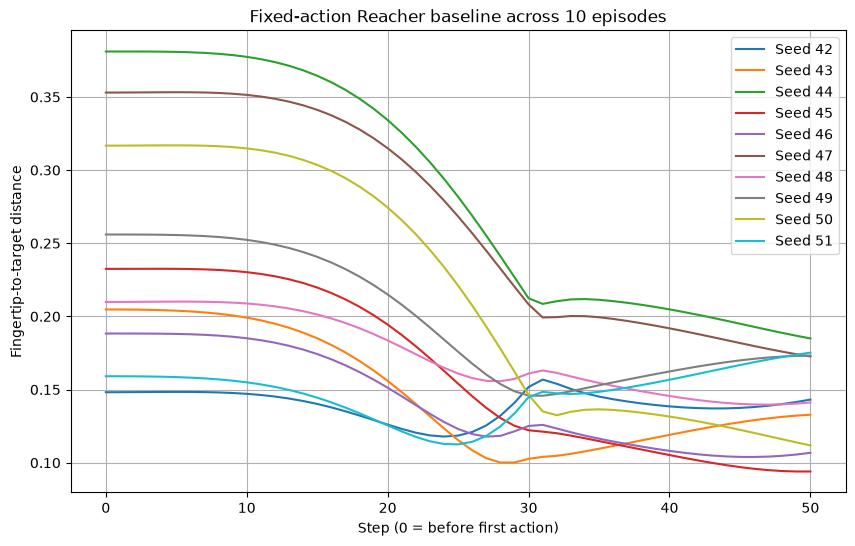

In [24]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

env = gym.make("Reacher-v5", render_mode="human")
action = np.array([0.05, -0.10], dtype=np.float32)
success_threshold = 0.05

plt.figure(figsize=(10, 6))
print("Seed | Start distance | Closest distance | Final distance | Total reward | Success")
print("-" * 85)

for seed in range(42, 52):
    observation, info = env.reset(seed=seed)
    distances = [np.linalg.norm(observation[8:10])]  # Step 0
    total_reward = 0.0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        observation, reward, terminated, truncated, info = env.step(action)
        distances.append(np.linalg.norm(observation[8:10]))
        total_reward += reward

    closest_distance = min(distances)
    success = closest_distance <= success_threshold

    print(
        f"{seed:4d} | {distances[0]:14.6f} | {closest_distance:16.6f} "
        f"| {distances[-1]:14.6f} | {total_reward:12.6f} | {success}"
    )

    plt.plot(range(len(distances)), distances, label=f"Seed {seed}")

env.close()

plt.xlabel("Step (0 = before first action)")
plt.ylabel("Fingertip-to-target distance")
plt.title("Fixed-action Reacher baseline across 10 episodes")
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

env = gym.make("Reacher-v5", render_mode="human")
action = np.array([0.05, -0.10], dtype=np.float32)
success_threshold = 0.05

plt.figure(figsize=(10, 6))
print("Seed | Start distance | Closest distance | Final distance | Total reward | Success")
print("-" * 85)

for seed in range(42, 52):
    observation, info = env.reset(seed=seed)
    distances = [np.linalg.norm(observation[8:10])]  # Step 0
    total_reward = 0.0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        observation, reward, terminated, truncated, info = env.step(action)
        distances.append(np.linalg.norm(observation[8:10]))
        total_reward += reward

    closest_distance = min(distances)
    success = closest_distance <= success_threshold

    print(
        f"{seed:4d} | {distances[0]:14.6f} | {closest_distance:16.6f} "
        f"| {distances[-1]:14.6f} | {total_reward:12.6f} | {success}"
    )

    plt.plot(range(len(distances)), distances, label=f"Seed {seed}")

env.close()

plt.xlabel("Step (0 = before first action)")
plt.ylabel("Fingertip-to-target distance")
plt.title("Fixed-action Reacher baseline across 10 episodes")
plt.grid(True)
plt.legend()
plt.show()

In [29]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

def policy(observation):
    x_offset = observation[8]
    
    if x_offset < 0:
        return np.array([0.05, -0.10], dtype=np.float32)
    else:
        return np.array([-0.05, -0.10], dtype=np.float32)
    
env = gym.make("Reacher-v5", render_mode="human")
observation, info = env.reset(seed=42)

terminated = False
truncated = False
step_number = 0

while not (terminated or truncated):
    x_offset = observation[8]
    action = policy(observation)
    print(f"Step {step_number + 1}: x_offset={x_offset:.6f}, action={action}")
    observation, reward, terminated, truncated, info = env.step(action)
    step_number += 1    
env.close()

Step 1: x_offset=0.105294, action=[-0.05 -0.1 ]
Step 2: x_offset=0.105332, action=[-0.05 -0.1 ]
Step 3: x_offset=0.105415, action=[-0.05 -0.1 ]
Step 4: x_offset=0.105470, action=[-0.05 -0.1 ]
Step 5: x_offset=0.105373, action=[-0.05 -0.1 ]
Step 6: x_offset=0.104961, action=[-0.05 -0.1 ]
Step 7: x_offset=0.104033, action=[-0.05 -0.1 ]
Step 8: x_offset=0.102354, action=[-0.05 -0.1 ]
Step 9: x_offset=0.099664, action=[-0.05 -0.1 ]
Step 10: x_offset=0.095687, action=[-0.05 -0.1 ]
Step 11: x_offset=0.090142, action=[-0.05 -0.1 ]
Step 12: x_offset=0.082761, action=[-0.05 -0.1 ]
Step 13: x_offset=0.073305, action=[-0.05 -0.1 ]
Step 14: x_offset=0.061589, action=[-0.05 -0.1 ]
Step 15: x_offset=0.047504, action=[-0.05 -0.1 ]
Step 16: x_offset=0.031043, action=[-0.05 -0.1 ]
Step 17: x_offset=0.012327, action=[-0.05 -0.1 ]
Step 18: x_offset=-0.008371, action=[ 0.05 -0.1 ]
Step 19: x_offset=-0.029983, action=[ 0.05 -0.1 ]
Step 20: x_offset=-0.051273, action=[ 0.05 -0.1 ]
Step 21: x_offset=-0.07160